# Seaborn Visualizations: Box Plot, Scatter Plot, and Pair Plot

## Learning objectives
By the end of this notebook, you will be able to:
- Explain when to use a box plot, scatter plot, and pair plot.
- Create each chart using Seaborn.
- Understand important parameters and interpret the chart.
- Complete practice questions and compare your answers with solutions.

**Notebook workflow:** Read the explanation, run the code cell, inspect the chart, and then try the activity before looking at its solution.

## 1. What is Seaborn?

Seaborn is a Python visualization library built on Matplotlib. It makes it easier to create statistical charts from data, especially data stored in a Pandas DataFrame.

We will continue using a student-performance use case. A training coordinator wants to understand students' marks, study hours, attendance, and academic branches.

In [3]:
import pandas as pd  # Work with tabular data
import seaborn as sns  # Create statistical charts
import matplotlib.pyplot as plt  # Configure figures and display plots

sns.set_theme(style="whitegrid")  # Apply a clean chart style

## 2. Create the sample dataset

The dataset is created inside the notebook, so you do not need an external CSV file.

- `Student`: student identifier
- `Branch`: academic branch
- `Study_Hours`: hours studied per day
- `Attendance`: attendance percentage
- `Marks`: marks out of 100

In [4]:
# Create a sample student dataset
df = pd.DataFrame({
    "Student": [f"S{i:02d}" for i in range(1, 16)],
    "Branch": ["CSE", "ECE", "CSE", "ME", "ECE", "CSE", "CE", "ME",
               "ECE", "CSE", "CE", "ECE", "CSE", "ME", "CE"],
    "Study_Hours": [1, 2, 5, 2, 4, 6, 3, 4, 5, 2, 6, 3, 7, 1, 4],
    "Attendance": [60, 65, 90, 58, 82, 96, 72, 75, 88, 62, 94, 80, 98, 55, 85],
    "Marks": [42, 50, 82, 45, 72, 95, 65, 70, 84, 48, 91, 74, 98, 40, 78]
})

display(df)  # Display all rows so we can inspect the data

,Student,Branch,Study_Hours,Attendance,Marks
0,S01,CSE,1,60,42
1,S02,ECE,2,65,50
2,S03,CSE,5,90,82
3,S04,ME,2,58,45
4,S05,ECE,4,82,72
5,S06,CSE,6,96,95
6,S07,CE,3,72,65
7,S08,ME,4,75,70
8,S09,ECE,5,88,84
9,S10,CSE,2,62,48


# Part A: Box Plot

## 3. What is a box plot?

A **box plot** summarizes the distribution of numerical data. It helps us compare the center and spread of values and identify possible outliers.

A standard box plot displays:
- **Median:** the line inside the box; half the observations are at or below it and half are at or above it.
- **First quartile (Q1):** the 25th percentile; the bottom of the box for a vertical box plot.
- **Third quartile (Q3):** the 75th percentile; the top of the box.
- **Interquartile range (IQR):** \(Q3 - Q1\), the range covered by the middle 50% of the data.
- **Whiskers:** extend to the most extreme data points within the usual outlier limits.
- **Potential outliers:** individual points beyond the whiskers.

By default, Seaborn's box plot uses the 1.5 × IQR rule for whiskers. A point beyond a whisker is a potential outlier, not automatically an error.

### Common `sns.boxplot()` parameters

| Parameter | Meaning |
|---|---|
| `data` | DataFrame containing the data |
| `x` | Category shown along the horizontal axis |
| `y` | Numerical variable whose distribution is summarized |
| `hue` | Splits each category into subgroups |
| `order` | Controls category order |
| `showfliers` | Shows (`True`) or hides (`False`) potential outlier points |
| `palette` | Selects colors for categories |
| `orient` | Sets orientation when needed; often inferred from `x` and `y` |

Use `x="Branch"` and `y="Marks"` to compare the distribution of marks across branches.

### Activity 1: Compare marks across branches

**Use case:** The training coordinator wants to know whether marks vary across branches and whether any students have unusually high or low marks.

**Question:** Which branch appears to have the highest median marks? Are any potential outliers shown?

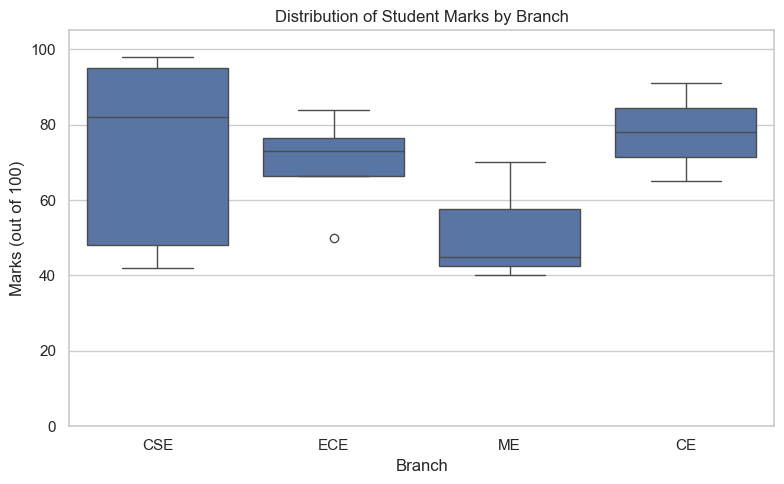

In [5]:
plt.figure(figsize=(8, 5))  # Create a figure with enough space for the categories
sns.boxplot(
    data=df,  # Use the student dataset
    x="Branch",  # Compare groups by branch
    y="Marks",  # Summarize the distribution of marks
    order=["CSE", "ECE", "ME", "CE"]  # Choose the order of branches
)
plt.title("Distribution of Student Marks by Branch")  # Add chart title
plt.xlabel("Branch")  # Label the horizontal axis
plt.ylabel("Marks (out of 100)")  # Label the vertical axis
plt.ylim(0, 105)  # Keep the marks scale easy to interpret
plt.tight_layout()  # Avoid overlapping labels
plt.show()  # Display the chart

### Explanation

- `sns.boxplot()` summarizes the distribution of marks within each branch.
- `x="Branch"` creates a separate box for each branch.
- `y="Marks"` tells Seaborn which numerical variable to summarize.
- `order` controls the order of branch labels.
- `plt.ylim(0, 105)` sets the displayed vertical range; it does not modify the marks in the dataset.

**How to read it:** Compare the horizontal median lines inside the boxes. A taller box means the middle 50% of marks covers a wider range. Points beyond whiskers, if present, are potential outliers according to the box-plot rule.

### Activity 2: Inspect potential outliers in marks

**Question:** Create a box plot of all students' marks without splitting by branch. Then compare it with the branch-wise box plot.

Hint: use `y="Marks"` and omit `x`.

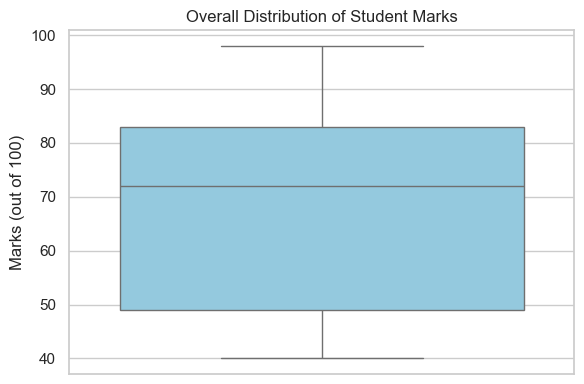

In [6]:
plt.figure(figsize=(6, 4))  # Create a compact figure

sns.boxplot(
    data=df,  # Use the student dataset
    y="Marks",  # Show the overall distribution of marks
    color="skyblue",  # Set a single box color
    showfliers=True  # Display potential outlier points
)

plt.title("Overall Distribution of Student Marks")  # Add chart title
plt.ylabel("Marks (out of 100)")  # Label the vertical axis
plt.tight_layout()  # Improve spacing
plt.show()  # Display the chart

### Important note about outliers

A box plot flags potential outliers based on the 1.5 × IQR rule. It does not tell us why a value is unusual. Before removing any point, investigate whether it is a data-entry error or a valid observation.

# Part B: Scatter Plot

## 4. What is a scatter plot?

A **scatter plot** shows the relationship between two numerical variables. Each dot represents one observation.

For example, we can explore whether students who study more hours tend to receive higher marks.

Common patterns:
- **Positive relationship:** as one variable increases, the other tends to increase.
- **Negative relationship:** as one variable increases, the other tends to decrease.
- **No clear relationship:** the points do not show a clear upward or downward pattern.

A visible relationship does not, by itself, prove that one variable causes the other.

### Common `sns.scatterplot()` parameters

| Parameter | Meaning |
|---|---|
| `data` | DataFrame containing the observations |
| `x` | Numerical variable on the horizontal axis |
| `y` | Numerical variable on the vertical axis |
| `hue` | Uses color to distinguish categories |
| `style` | Uses marker styles to distinguish categories |
| `size` | Maps marker size to a variable |
| `alpha` | Controls transparency from 0 (transparent) to 1 (opaque) |
| `s` | Sets marker size when a fixed size is preferred |
| `legend` | Controls the legend display |

Use a scatter plot when you want to see how two numerical columns vary together.

### Activity 3: Study hours and marks

**Use case:** The coordinator wants to explore whether study hours are associated with marks.

**Question:** Does the plot suggest a positive, negative, or unclear relationship between study hours and marks?

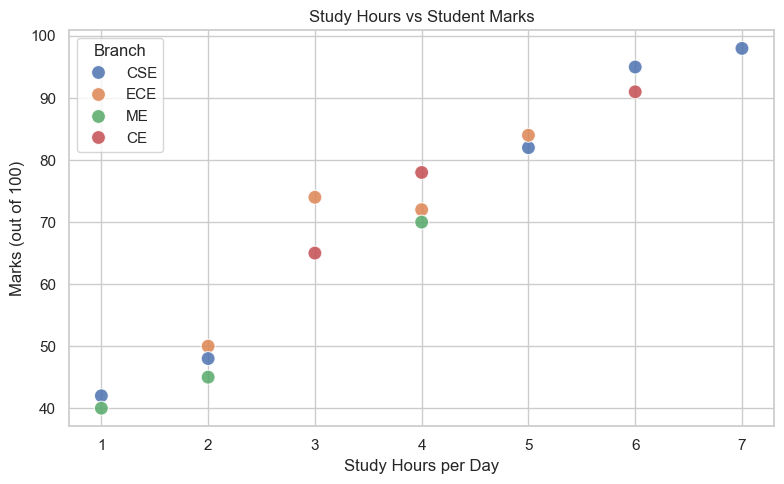

In [7]:
plt.figure(figsize=(8, 5))  # Set the figure dimensions

sns.scatterplot(
    data=df,  # Use the student dataset
    x="Study_Hours",  # Put study hours on the horizontal axis
    y="Marks",  # Put marks on the vertical axis
    hue="Branch",  # Use color to distinguish branches
    s=100,  # Increase marker size for visibility
    alpha=0.85  # Make markers slightly transparent
)

plt.title("Study Hours vs Student Marks")  # Add chart title
plt.xlabel("Study Hours per Day")  # Label x-axis
plt.ylabel("Marks (out of 100)")  # Label y-axis
plt.legend(title="Branch")  # Add a descriptive legend title
plt.tight_layout()  # Adjust spacing
plt.show()  # Display the chart

### Explanation

- `x="Study_Hours"` and `y="Marks"` place the two numerical variables on the axes.
- Each dot represents one student.
- `hue="Branch"` colors students by academic branch.
- `s=100` makes the markers larger.
- `alpha=0.85` makes the markers slightly transparent.

**Interpretation:** Look for the overall direction of the dots. If marks generally rise as study hours rise, the plot suggests a positive association. Other factors—such as attendance, prior knowledge, or study quality—may also affect marks.

### Activity 4: Attendance and marks

**Question:** Create a scatter plot with attendance on the x-axis and marks on the y-axis. Use marker style to distinguish branches.

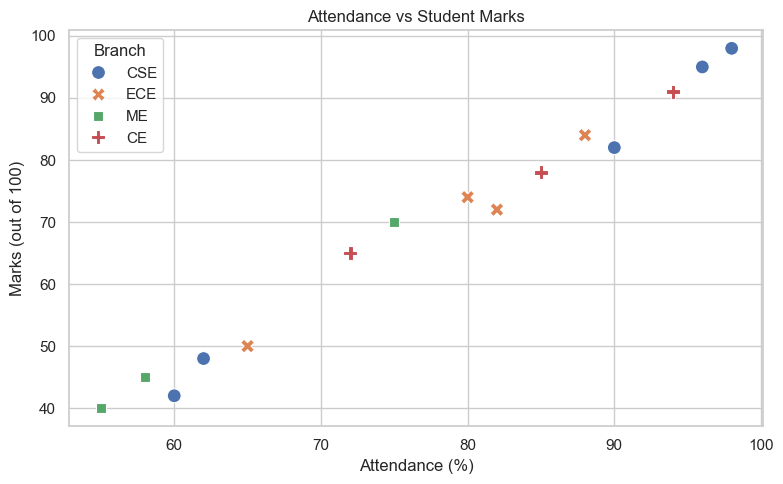

In [8]:
plt.figure(figsize=(8, 5))  # Set the figure dimensions

sns.scatterplot(
    data=df,  # Use the student dataset
    x="Attendance",  # Put attendance on the horizontal axis
    y="Marks",  # Put marks on the vertical axis
    style="Branch",  # Use different marker styles for branches
    hue="Branch",  # Also use colors to distinguish branches
    s=100  # Make markers easier to see
)

plt.title("Attendance vs Student Marks")  # Add chart title
plt.xlabel("Attendance (%)")  # Label x-axis
plt.ylabel("Marks (out of 100)")  # Label y-axis
plt.tight_layout()  # Improve spacing
plt.show()  # Display the chart

### Optional: Calculate correlation

A scatter plot gives a visual impression. Correlation provides a numerical summary of the strength and direction of a **linear** relationship. Pearson correlation ranges from -1 to +1.

- Near +1: strong positive linear relationship.
- Near -1: strong negative linear relationship.
- Near 0: little or no linear relationship.

Correlation does not establish causation.

In [9]:
correlation = df["Study_Hours"].corr(df["Marks"])  # Calculate Pearson correlation
print("Correlation between study hours and marks:", round(correlation, 3))  # Print rounded result

Correlation between study hours and marks: 0.973


# Part C: Pair Plot

## 5. What is a pair plot?

A **pair plot** displays pairwise relationships among several numerical variables in one figure.

It usually includes:
- **Scatter plots** in the off-diagonal panels, showing relationships between pairs of numerical variables.
- **Distributions** on the diagonal, showing how each individual numerical variable is distributed.

A pair plot is useful during exploratory data analysis (EDA) when you want to examine several numerical variables together before choosing a more focused analysis.

Pair plots can become crowded with many columns or rows, so use a small set of relevant numerical variables.

### Common `sns.pairplot()` parameters

| Parameter | Meaning |
|---|---|
| `data` | DataFrame with the variables to plot |
| `vars` | List of numerical columns to include |
| `hue` | Colors observations by a category |
| `kind` | Type of off-diagonal plot; commonly `"scatter"` or `"reg"` |
| `diag_kind` | Type of diagonal plot; commonly `"hist"` or `"kde"` |
| `corner` | If `True`, shows only one triangle of pairwise plots |
| `plot_kws` | Dictionary of options passed to off-diagonal plots |
| `diag_kws` | Dictionary of options passed to diagonal plots |

`pairplot()` returns a Seaborn `PairGrid`, so it is commonly used directly rather than wrapped in `plt.figure()`.

### Activity 5: Explore relationships across numerical variables

**Use case:** The coordinator wants an initial overview of how study hours, attendance, and marks relate to one another.

**Question:** Which pairs of variables appear to have an upward pattern? Do the diagonal plots show that all three variables have the same distribution?

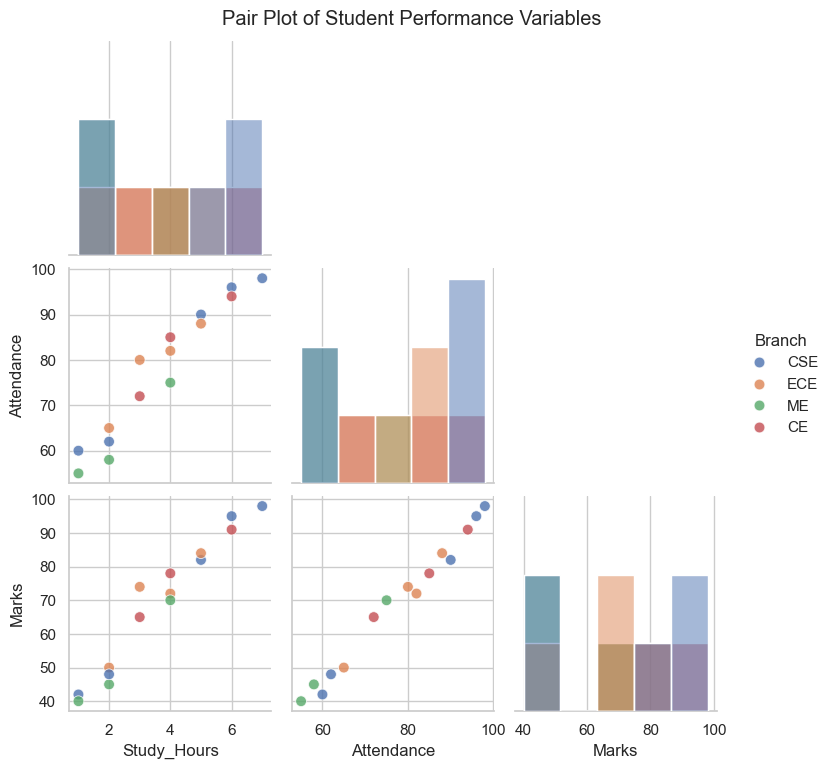

In [10]:
sns.pairplot(
    data=df,  # Use the student dataset
    vars=["Study_Hours", "Attendance", "Marks"],  # Select numerical columns
    hue="Branch",  # Color points by academic branch
    diag_kind="hist",  # Show histograms on the diagonal
    corner=True,  # Display only the lower triangle to reduce repetition
    plot_kws={"s": 60, "alpha": 0.8}  # Set marker size and transparency
)

plt.suptitle("Pair Plot of Student Performance Variables", y=1.02)  # Add an overall title
plt.show()  # Display the pair plot

### How to interpret a pair plot

1. Read the column and row labels to identify the variables being compared.
2. In off-diagonal panels, look for upward, downward, or unclear patterns.
3. On the diagonal, inspect each variable's distribution.
4. Use the colors to compare branches.
5. Treat patterns as clues for further analysis, not proof of cause and effect.

The `corner=True` option avoids displaying both a scatter plot and its mirrored duplicate for the same pair of variables.

## 6. Practice Questions

Try each question in a new code cell before checking the solutions.

### Question 1 — Box plot
Create a box plot showing the distribution of `Attendance` for each `Branch`. Add a title and axis labels.

### Question 2 — Scatter plot
Create a scatter plot of `Study_Hours` versus `Marks`. Color the points by `Branch`.

### Question 3 — Scatter plot styling
Create a scatter plot of `Attendance` versus `Marks`. Use marker size `120` and transparency `0.7`.

### Question 4 — Pair plot
Create a pair plot using `Study_Hours`, `Attendance`, and `Marks`, with `Branch` as `hue`.

### Question 5 — Choose the right chart
Choose a box plot, scatter plot, or pair plot for each task:
- A. Compare the distribution of marks across branches.
- B. Explore the relationship between attendance and marks.
- C. Explore relationships among study hours, attendance, and marks together.

## 7. Practice Solutions

### Solution 1 — Attendance distribution by branch

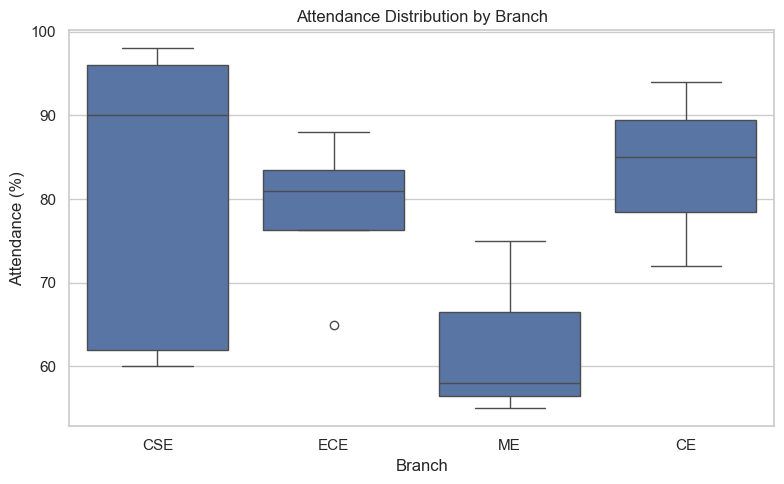

In [11]:
plt.figure(figsize=(8, 5))  # Create the figure
sns.boxplot(data=df, x="Branch", y="Attendance")  # Compare attendance distributions by branch
plt.title("Attendance Distribution by Branch")  # Add title
plt.xlabel("Branch")  # Label x-axis
plt.ylabel("Attendance (%)")  # Label y-axis
plt.tight_layout()  # Adjust spacing
plt.show()  # Display plot

### Solution 2 — Study hours versus marks

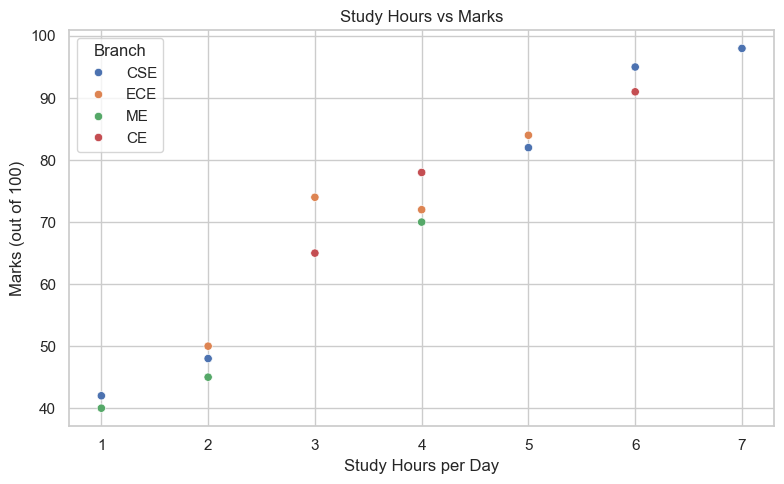

In [12]:
plt.figure(figsize=(8, 5))  # Create the figure
sns.scatterplot(data=df, x="Study_Hours", y="Marks", hue="Branch")  # Plot relationship and color by branch
plt.title("Study Hours vs Marks")  # Add title
plt.xlabel("Study Hours per Day")  # Label x-axis
plt.ylabel("Marks (out of 100)")  # Label y-axis
plt.tight_layout()  # Adjust spacing
plt.show()  # Display plot

### Solution 3 — Attendance versus marks with marker settings

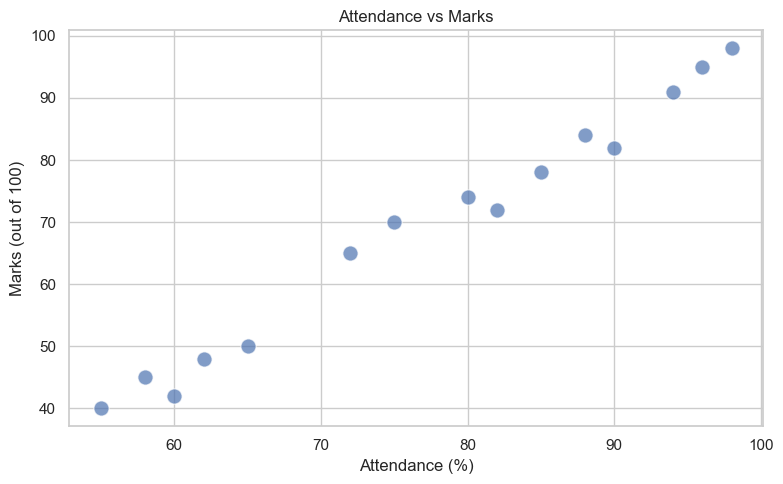

In [13]:
plt.figure(figsize=(8, 5))  # Create the figure
sns.scatterplot(
    data=df,  # Use the student data
    x="Attendance",  # Set x variable
    y="Marks",  # Set y variable
    s=120,  # Set marker size
    alpha=0.7  # Set marker transparency
)
plt.title("Attendance vs Marks")  # Add title
plt.xlabel("Attendance (%)")  # Label x-axis
plt.ylabel("Marks (out of 100)")  # Label y-axis
plt.tight_layout()  # Adjust spacing
plt.show()  # Display plot

### Solution 4 — Pair plot

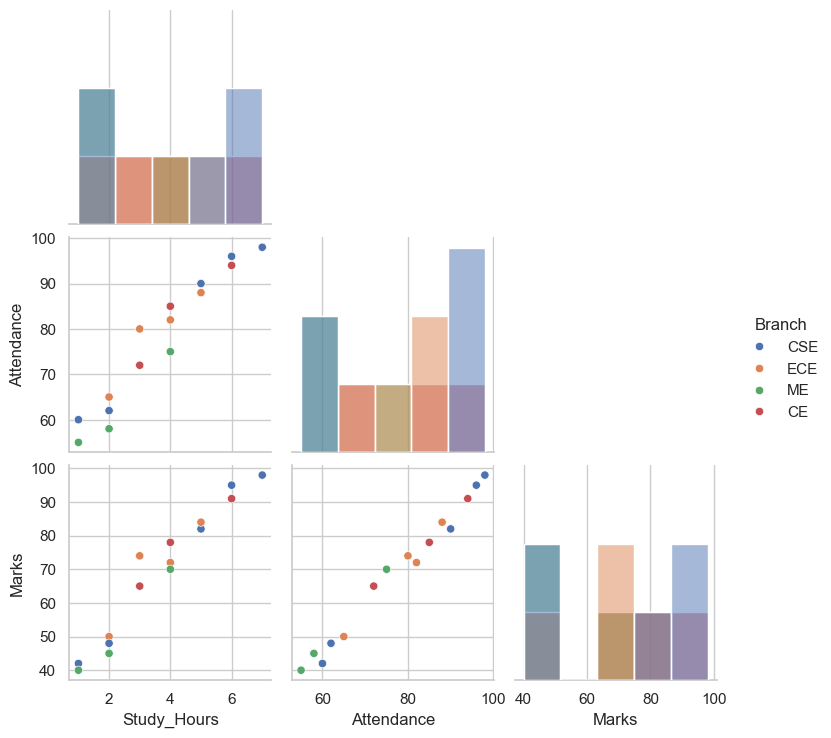

In [14]:
sns.pairplot(
    data=df,  # Use the student data
    vars=["Study_Hours", "Attendance", "Marks"],  # Choose the numerical variables
    hue="Branch",  # Color by branch
    diag_kind="hist",  # Use histograms on the diagonal
    corner=True  # Avoid duplicate mirrored panels
)
plt.show()  # Display the pair plot

### Solution 5 — Choose the right chart

- **A: Box plot** — compares distributions, medians, spread, and potential outliers across branches.
- **B: Scatter plot** — shows the relationship between two numerical variables.
- **C: Pair plot** — provides a grid of pairwise relationships for several numerical variables.

## 8. Quick Reference

```python
# Compare a numerical distribution across categories
sns.boxplot(data=df, x="Branch", y="Marks")

# Explore the relationship between two numerical variables
sns.scatterplot(data=df, x="Study_Hours", y="Marks")

# Color scatter points by a category
sns.scatterplot(data=df, x="Study_Hours", y="Marks", hue="Branch")

# Explore several numerical variables at once
sns.pairplot(
    data=df,
    vars=["Study_Hours", "Attendance", "Marks"],
    hue="Branch",
    corner=True
)
```

### Final takeaway
- Use **box plots** to compare distributions and spot potential outliers.
- Use **scatter plots** to explore relationships between two numerical variables.
- Use **pair plots** to inspect pairwise relationships among several numerical variables.

## Violin Plot

A **violin plot** is a data visualization used to understand the distribution of numerical data across one or more categories. It combines features of a **box plot** and a **KDE (Kernel Density Estimation) plot**.

### How to Read a Violin Plot

- **Width of the violin:** Wider regions indicate a higher concentration of data values, while narrower regions indicate fewer observations.
- **Shape:** Shows the distribution and spread of the data.
- **Median:** When displayed, the line inside the violin represents the median value.
- **Quartiles:** When displayed, these indicate the middle 50% of the data.
- **Multiple categories:** Allows us to compare distributions across different groups.

### Why Use a Violin Plot?

- To understand the shape of a data distribution.
- To identify areas where values are concentrated.
- To compare the distribution of numerical data across categories.
- To identify skewness or multiple peaks in a distribution.
- To understand more detail about a distribution than a basic box plot may provide.

### Violin Plot vs Box Plot

| Feature | Violin Plot | Box Plot |
|---|---|---|
| Distribution shape | Yes | No |
| Data density | Yes | No |
| Median | Can be displayed | Yes |
| Quartiles | Optional | Yes |
| Potential outliers | Not usually shown individually | Usually shown individually |
| Best use | Understanding distribution shape | Comparing summary statistics and outliers |

### Common Seaborn Parameters

- `data`: The DataFrame containing the data.
- `x`: The categorical variable.
- `y`: The numerical variable.
- `hue`: An optional variable used to divide data into groups using different colors.
- `inner`: Controls the information displayed inside the violin, such as `"box"`, `"quart"`, `"point"`, `"stick"`, or `None`.
- `palette`: Controls the colors used for categories.
- `cut`: Controls how far the KDE extends beyond the observed data range.

### Example Use Case

A restaurant manager wants to compare restaurant bill distributions across different days of the week. A violin plot can show where bills are concentrated and whether the distribution differs between Thursday, Friday, Saturday, and Sunday.

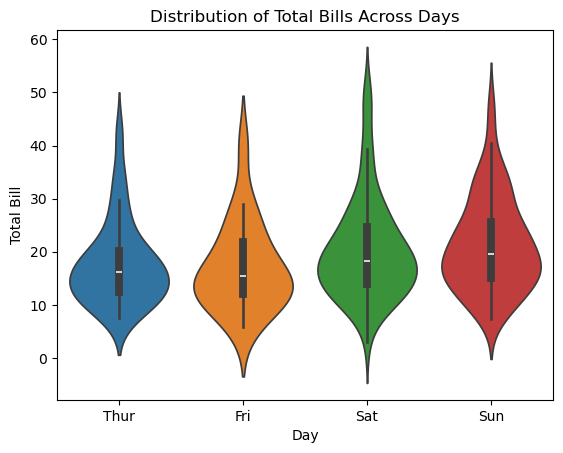

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt

# Load the built-in restaurant tips dataset
df = sns.load_dataset("tips")

# Create a violin plot to compare bill distributions across days
sns.violinplot(
    data=df,
    x="day",
    y="total_bill",
    hue="day",
    inner="box",
    legend=False
)

# Add chart title and axis labels
plt.title("Distribution of Total Bills Across Days")
plt.xlabel("Day")
plt.ylabel("Total Bill")

# Display the chart
plt.show()

## Heatmap

A **heatmap** is a data visualization technique that represents numerical values using different colors. It helps identify patterns, relationships, and variations in data quickly.

### How to Read a Heatmap

- **Rows and columns:** Represent variables or categories.
- **Colors:** Represent the magnitude of values.
- **Color intensity:** Usually indicates whether values are relatively high or low, depending on the color scale.
- **Annotations:** Optional numerical values displayed inside each cell.
- **Color bar:** Explains how colors correspond to numerical values.

### Why Use a Heatmap?

- To identify correlations between numerical variables.
- To find patterns and trends in large datasets.
- To compare values across categories.
- To identify strong positive and negative relationships.
- To visualize missing values in a dataset.

### Common Seaborn Parameters

- `data`: The DataFrame or matrix containing values.
- `annot=True`: Displays numerical values inside the cells.
- `cmap`: Specifies the color palette, such as `"coolwarm"`, `"viridis"`, or `"Blues"`.
- `linewidths`: Adds spacing between cells.
- `fmt=".2f"`: Displays annotated numbers to two decimal places.
- `cbar=True`: Displays the color bar.

### Common Use Cases

- **Correlation heatmap:** Understand relationships between numerical variables.
- **Sales heatmap:** Compare sales across days and months.
- **Student performance heatmap:** Compare marks across subjects and students.
- **Missing-value heatmap:** Identify columns and rows containing missing data.

### Advantages

- Makes large numerical tables easier to understand.
- Highlights patterns and extreme values quickly.
- Helps identify relationships between variables.

### Limitations

- The color scale can influence how values are perceived.
- Correlation does not imply causation.
- Too many rows and columns can make a heatmap difficult to read.

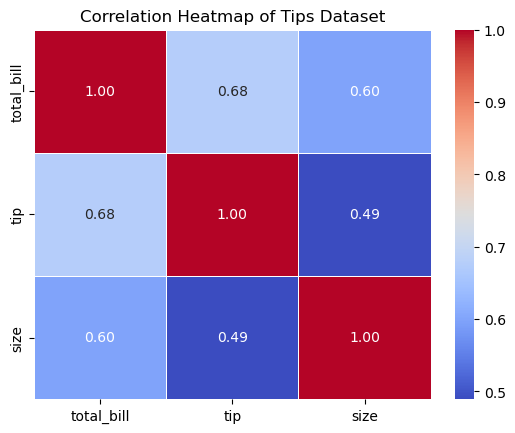

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt

# Load the restaurant tips dataset
df = sns.load_dataset("tips")

# Select numerical columns and calculate correlations
corr = df.select_dtypes(include="number").corr()

# Create the heatmap
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

# Add a title
plt.title("Correlation Heatmap of Tips Dataset")

plt.show()

## Explanation of the Correlation Heatmap Code

### 1. Import Libraries

```python
import seaborn as sns
import matplotlib.pyplot as plt
```

- `seaborn`: Used to create statistical visualizations, including heatmaps.
- `matplotlib.pyplot`: Used to customize the chart, add titles, and display the plot.

### 2. Load the Dataset

```python
df = sns.load_dataset("tips")
```

- Loads Seaborn's built-in `tips` dataset into a Pandas DataFrame called `df`.
- The dataset contains information about restaurant bills, tips, customer gender, smoking status, day, time, and party size.

### 3. Select Numerical Columns and Calculate Correlations

```python
corr = df.select_dtypes(include="number").corr()
```

This line performs two operations:

- `select_dtypes(include="number")`: Selects only numerical columns, such as `total_bill`, `tip`, and `size`.
- `.corr()`: Calculates the pairwise Pearson correlation coefficients between the selected numerical columns by default.

Pearson correlation is a statistical method used to measure the strength and direction of the linear relationship between two numerical variables.
For example, in data analytics, we can use Pearson correlation to check whether students who study more hours tend to score higher marks.

The correlation values range from `-1` to `+1`.

- `+1`: Perfect positive linear correlation.
- `-1`: Perfect negative linear correlation.
- `0`: No linear correlation.

### 4. Create the Heatmap

```python
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)
```

This function converts the correlation matrix into a color-coded heatmap.

- `corr`: The correlation matrix to visualize.
- `annot=True`: Displays the numerical correlation values inside each cell.
- `cmap="coolwarm"`: Uses a color palette with contrasting cool and warm colors to distinguish lower and higher correlation values.
- `fmt=".2f"`: Displays each value rounded to two decimal places.
- `linewidths=0.5`: Adds thin spaces between the cells for better readability.

### 5. Add a Title

```python
plt.title("Correlation Heatmap of Tips Dataset")
```

Adds a descriptive title at the top of the visualization.

### 6. Display the Chart

```python
plt.show()
```

Displays the completed heatmap.

### How to Interpret the Heatmap

- **Strong positive correlation:** As one variable increases, the other tends to increase.
- **Strong negative correlation:** As one variable increases, the other tends to decrease.
- **Weak correlation:** There is little evidence of a linear relationship.
- **Diagonal values:** Always equal `1.00`, because each variable is perfectly correlated with itself.
- **Symmetrical matrix:** The correlation between A and B is the same as the correlation between B and A.

### Important Note

Correlation measures association, not causation. A strong correlation does not prove that one variable causes a change in another. Also, a correlation close to zero does not rule out a nonlinear relationship.